# From a glycerol–water mixture to $Re$–$Ca$ space

This notebook reverses the original question. Rather than choosing $(Re,Ca,\theta)$ and searching for a possible fluid, we prescribe:

1. glycerol mass fraction,
2. inclination angle $\theta$,
3. mean film thickness $h_0$,

and calculate the Nusselt mean velocity and resulting Reynolds and capillary numbers.

All mixture properties below are for approximately **20 °C**. Concentration is **glycerol mass percent (wt%)**, not volume percent. Temperature must be stated because the viscosity—especially near pure glycerol—is strongly temperature dependent.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.interpolate import PchipInterpolator
from pathlib import Path

gravity = 9.81
temperature_C = 20.0

# User controls
angles_deg = np.array([6.4, 30.0, 45.0, 60.0, 90.0])
h0_values = np.logspace(np.log10(0.10e-3), np.log10(2.00e-3), 250)
glycerol_wt_values = np.linspace(0.0, 100.0, 201)

# Optional experimental screen (does not alter Re or Ca calculations)
velocity_limits_m_s = (0.0, 0.50)

# Optional DNS parameter-space overlay
dns_Re = np.array([5, 10, 20, 40, 60, 80, 100, 120, 160, 200], dtype=float)
dns_Ca = np.array([0.001, 0.002, 0.005, 0.01, 0.02, 0.04, 0.06, 0.1], dtype=float)


## Governing relations

For a steady laminar Nusselt film down an incline,

$$U_N=\frac{\rho g\sin\theta\,h_0^2}{3\mu}.$$

Using the same definitions as the original notebook,

$$Re=\frac{\rho U_Nh_0}{\mu}
=\frac{\rho^2g\sin\theta\,h_0^3}{3\mu^2},$$

$$Ca=\frac{\mu U_N}{\sigma}
=\frac{\rho g\sin\theta\,h_0^2}{3\sigma}.$$

Thus $Re\propto h_0^3/\mu^2$, whereas $Ca\propto h_0^2/\sigma$. Under this Nusselt scaling, viscosity cancels from $Ca$; glycerol concentration therefore moves a case much more strongly in $Re$ than in $Ca$. These relations assume a fully developed, laminar, gravity-driven film with a shear-free liquid–gas interface and no imposed gas shear or streamwise pressure gradient.

## Glycerol–water properties at 20 °C

The anchor table covers pure water through nominally pure glycerol in 10 wt% increments. Density and viscosity values are representative literature values at 20 °C; surface tension varies comparatively weakly and is interpolated between representative aqueous-solution values. Shape-preserving interpolation avoids overshoot between anchors.

For publication-quality property work, replace the anchors with values from the exact glycerol grade and measured laboratory temperature. Useful sources are Cheng (2008) for the full-range viscosity correlation and Takamura, Fischer & Morrow (2012) for aqueous-glycerol properties.

In [2]:
property_table = pd.DataFrame({
    "glycerol_wt_percent": [0, 10, 20, 30, 40, 50, 60, 70, 80, 90, 100],
    "rho_kg_m3":           [998.2, 1023.3, 1047.6, 1072.7, 1099.6, 1128.7, 1158.6, 1187.9, 1217.0, 1244.6, 1261.3],
    "mu_mPa_s":            [1.002, 1.31, 1.76, 2.50, 3.72, 6.00, 10.8, 22.5, 60.1, 219.0, 1412.0],
    "sigma_mN_m":          [72.75, 72.0, 71.3, 70.5, 69.7, 68.8, 67.9, 66.9, 65.9, 64.8, 63.4],
})
property_table


,glycerol_wt_percent,rho_kg_m3,mu_mPa_s,sigma_mN_m
0,0,998.2,1.002,72.75
1,10,1023.3,1.310,72.00
2,20,1047.6,1.760,71.30
3,30,1072.7,2.500,70.50
4,40,1099.6,3.720,69.70
5,50,1128.7,6.000,68.80
6,60,1158.6,10.800,67.90
7,70,1187.9,22.500,66.90
8,80,1217.0,60.100,65.90
9,90,1244.6,219.000,64.80


In [3]:
rho_interp = PchipInterpolator(property_table["glycerol_wt_percent"], property_table["rho_kg_m3"])

# Interpolate log(mu), because viscosity changes by over three orders of magnitude.
log_mu_interp = PchipInterpolator(
    property_table["glycerol_wt_percent"],
    np.log(property_table["mu_mPa_s"] * 1e-3),
)
sigma_interp = PchipInterpolator(
    property_table["glycerol_wt_percent"],
    property_table["sigma_mN_m"] * 1e-3,
)

def glycerol_water_properties(glycerol_wt_percent):
    # Return rho [kg/m3], mu [Pa s], sigma [N/m] at about 20 C.
    w = np.asarray(glycerol_wt_percent, dtype=float)
    if np.any((w < 0.0) | (w > 100.0)):
        raise ValueError("glycerol_wt_percent must be between 0 and 100")
    return rho_interp(w), np.exp(log_mu_interp(w)), sigma_interp(w)

property_table.round({"rho_kg_m3": 1, "mu_mPa_s": 3, "sigma_mN_m": 2})


,glycerol_wt_percent,rho_kg_m3,mu_mPa_s,sigma_mN_m
0,0,998.2,1.002,72.75
1,10,1023.3,1.310,72.00
2,20,1047.6,1.760,71.30
3,30,1072.7,2.500,70.50
4,40,1099.6,3.720,69.70
5,50,1128.7,6.000,68.80
6,60,1158.6,10.800,67.90
7,70,1187.9,22.500,66.90
8,80,1217.0,60.100,65.90
9,90,1244.6,219.000,64.80


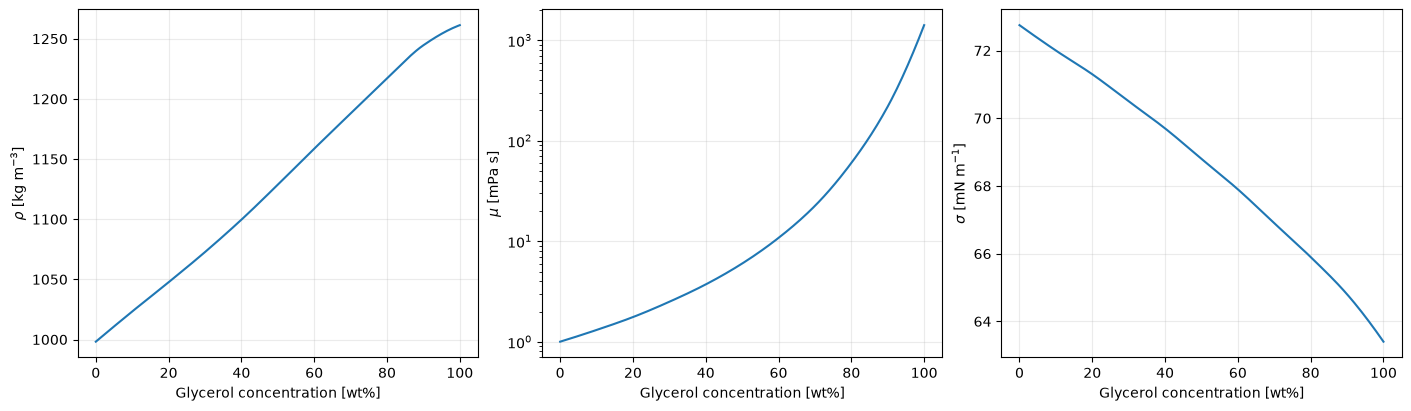

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4), constrained_layout=True)
w_plot = glycerol_wt_values
rho_plot, mu_plot, sigma_plot = glycerol_water_properties(w_plot)

axes[0].plot(w_plot, rho_plot)
axes[0].set_ylabel(r"$\rho$ [kg m$^{-3}$]")
axes[1].semilogy(w_plot, 1e3 * mu_plot)
axes[1].set_ylabel(r"$\mu$ [mPa s]")
axes[2].plot(w_plot, 1e3 * sigma_plot)
axes[2].set_ylabel(r"$\sigma$ [mN m$^{-1}$]")
for ax in axes:
    ax.set_xlabel("Glycerol concentration [wt%]")
    ax.grid(alpha=0.25)
plt.show()


## Calculate one physical case

In [5]:
def evaluate_physical_case(glycerol_wt_percent, angle_deg, h0, gravity=9.81):
    # Calculate properties, Nusselt velocity, Re and Ca for one physical case.
    if h0 <= 0:
        raise ValueError("h0 must be positive")
    if not (0 < angle_deg <= 90):
        raise ValueError("angle_deg must lie in (0, 90]")

    rho, mu, sigma = glycerol_water_properties(glycerol_wt_percent)
    sin_theta = np.sin(np.radians(angle_deg))
    velocity = rho * gravity * sin_theta * h0**2 / (3.0 * mu)
    Re = rho * velocity * h0 / mu
    Ca = mu * velocity / sigma

    return {
        "glycerol_wt_percent": float(glycerol_wt_percent),
        "angle_deg": float(angle_deg),
        "h0_m": float(h0),
        "rho_kg_m3": float(rho),
        "mu_Pa_s": float(mu),
        "sigma_N_m": float(sigma),
        "velocity_m_s": float(velocity),
        "Re": float(Re),
        "Ca": float(Ca),
    }

chosen_case = evaluate_physical_case(
    glycerol_wt_percent=60.0,
    angle_deg=6.4,
    h0=1.0e-3,
)
pd.Series(chosen_case)


glycerol_wt_percent      60.000000
angle_deg                 6.400000
h0_m                      0.001000
rho_kg_m3              1158.600000
mu_Pa_s                   0.010800
sigma_N_m                 0.067900
velocity_m_s              0.039103
Re                        4.194895
Ca                        0.006220
dtype: float64

## Sweep concentration, thickness and angle

In [6]:
def build_parameter_map(glycerol_wt_values, h0_values, angles_deg, gravity=9.81):
    rows = []
    for angle_deg in np.atleast_1d(angles_deg):
        for glycerol_wt in np.atleast_1d(glycerol_wt_values):
            rho, mu, sigma = glycerol_water_properties(glycerol_wt)
            sin_theta = np.sin(np.radians(angle_deg))
            U = rho * gravity * sin_theta * h0_values**2 / (3.0 * mu)
            Re = rho * U * h0_values / mu
            Ca = mu * U / sigma
            for h0, u, re, ca in zip(h0_values, U, Re, Ca):
                rows.append({
                    "glycerol_wt_percent": glycerol_wt,
                    "angle_deg": angle_deg,
                    "h0_m": h0,
                    "h0_mm": 1e3 * h0,
                    "rho_kg_m3": rho,
                    "mu_Pa_s": mu,
                    "sigma_N_m": sigma,
                    "velocity_m_s": u,
                    "Re": re,
                    "Ca": ca,
                    "velocity_realistic": velocity_limits_m_s[0] <= u <= velocity_limits_m_s[1],
                })
    return pd.DataFrame(rows)

parameter_map = build_parameter_map(glycerol_wt_values, h0_values, angles_deg)
parameter_map.head()


,glycerol_wt_percent,angle_deg,h0_m,h0_mm,rho_kg_m3,mu_Pa_s,sigma_N_m,velocity_m_s,Re,Ca,velocity_realistic
0,0.0,6.4,0.000100,0.100000,998.2,0.001002,0.07275,0.003631,0.361744,0.000050,True
1,0.0,6.4,0.000101,0.101210,998.2,0.001002,0.07275,0.003720,0.375039,0.000051,True
2,0.0,6.4,0.000102,0.102435,998.2,0.001002,0.07275,0.003810,0.388823,0.000052,True
3,0.0,6.4,0.000104,0.103675,998.2,0.001002,0.07275,0.003903,0.403113,0.000054,True
4,0.0,6.4,0.000105,0.104930,998.2,0.001002,0.07275,0.003998,0.417928,0.000055,True


In [7]:
summary_by_angle = (
    parameter_map.groupby("angle_deg")
    .agg(Re_min=("Re", "min"), Re_max=("Re", "max"),
         Ca_min=("Ca", "min"), Ca_max=("Ca", "max"),
         U_min_m_s=("velocity_m_s", "min"), U_max_m_s=("velocity_m_s", "max"))
)
summary_by_angle


,Re_min,Re_max,Ca_min,Ca_max,U_min_m_s,U_max_m_s
angle_deg,,,,,,
6.4,2.908499e-07,2893.951634,0.000050,0.029006,0.000003,1.452484
30.0,1.304623e-06,12980.978541,0.000224,0.130109,0.000015,6.515198
45.0,1.845016e-06,18357.875906,0.000317,0.184002,0.000021,9.213881
60.0,2.259674e-06,22483.714365,0.000389,0.225355,0.000025,11.284653
90.0,2.609247e-06,25961.957082,0.000449,0.260218,0.000029,13.030395


In [8]:
# Ranges after applying only the selected experimental velocity screen
screened_map = parameter_map[parameter_map["velocity_realistic"]]
screened_summary_by_angle = (
    screened_map.groupby("angle_deg")
    .agg(Re_min=("Re", "min"), Re_max=("Re", "max"),
         Ca_min=("Ca", "min"), Ca_max=("Ca", "max"),
         U_min_m_s=("velocity_m_s", "min"), U_max_m_s=("velocity_m_s", "max"))
)
screened_summary_by_angle


,Re_min,Re_max,Ca_min,Ca_max,U_min_m_s,U_max_m_s
angle_deg,,,,,,
6.4,2.908499e-07,577.852614,0.000050,0.029006,0.000003,0.499775
30.0,1.304623e-06,272.945533,0.000224,0.130109,0.000015,0.499761
45.0,1.845016e-06,227.598088,0.000317,0.184002,0.000021,0.499885
60.0,2.259674e-06,206.115302,0.000389,0.225355,0.000025,0.499877
90.0,2.609247e-06,191.659011,0.000449,0.260218,0.000029,0.499864


### Heat maps in physical-input space

These plots answer: *for a chosen angle, which $Re$ and $Ca$ result from each glycerol concentration and film thickness?*

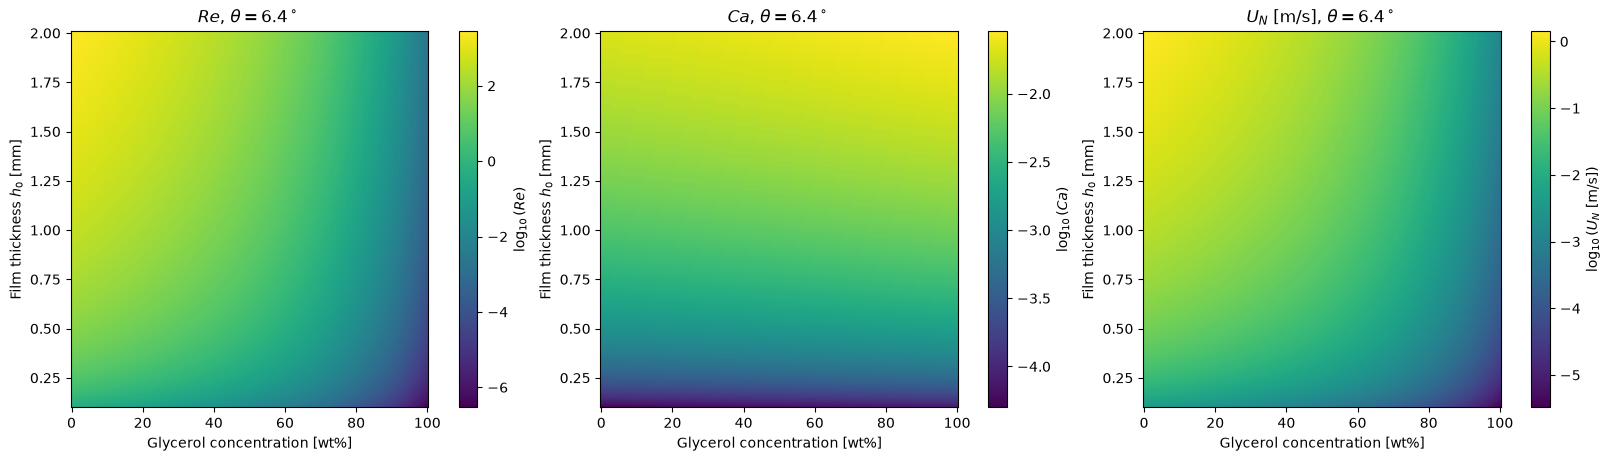

In [9]:
chosen_angle = 6.4
angle_map = parameter_map[parameter_map["angle_deg"] == chosen_angle]

def pivot_value(column):
    return angle_map.pivot(index="h0_mm", columns="glycerol_wt_percent", values=column)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), constrained_layout=True)
for ax, column, title, log_color in zip(
    axes,
    ["Re", "Ca", "velocity_m_s"],
    [r"$Re$", r"$Ca$", r"$U_N$ [m/s]"],
    [True, True, True],
):
    matrix = pivot_value(column)
    values = np.log10(matrix.values) if log_color else matrix.values
    mesh = ax.pcolormesh(matrix.columns, matrix.index, values, shading="auto")
    cbar = fig.colorbar(mesh, ax=ax)
    cbar.set_label(rf"$\log_{{10}}$({title})" if log_color else title)
    ax.set_xlabel("Glycerol concentration [wt%]")
    ax.set_ylabel(r"Film thickness $h_0$ [mm]")
    ax.set_title(rf"{title}, $\theta={chosen_angle:g}^\circ$")
plt.show()


### Curves in the $Re$–$Ca$ plane

Each curve holds concentration fixed and varies thickness from 0.10 to 2.00 mm. Markers indicate selected thicknesses. The black crosses show the discrete DNS design points.

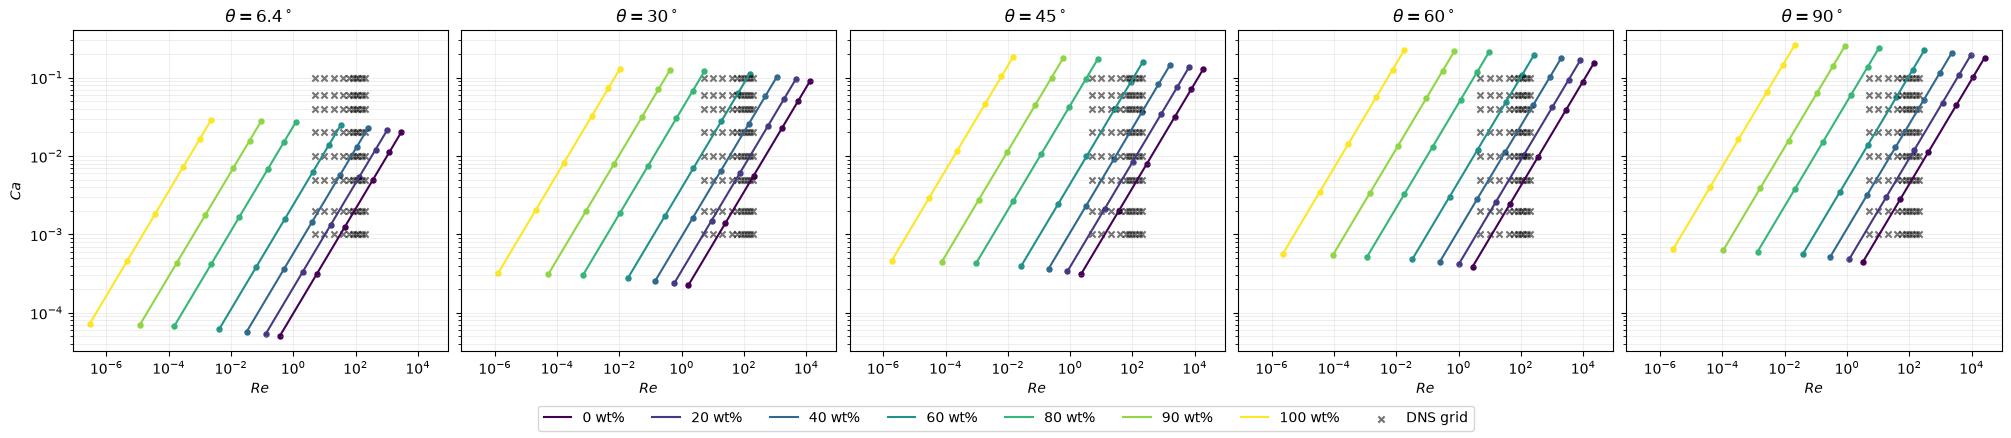

In [10]:
chosen_concentrations = [0, 20, 40, 60, 80, 90, 100]
marker_h0_mm = np.array([0.10, 0.25, 0.50, 1.00, 1.50, 2.00])

fig, axes = plt.subplots(1, len(angles_deg), figsize=(20, 4.3), sharex=True, sharey=True, constrained_layout=True)
colors = plt.cm.viridis(np.linspace(0, 1, len(chosen_concentrations)))

for ax, angle_deg in zip(np.atleast_1d(axes), angles_deg):
    for color, wt in zip(colors, chosen_concentrations):
        line = parameter_map[(parameter_map["angle_deg"] == angle_deg) & np.isclose(parameter_map["glycerol_wt_percent"], wt)]
        ax.plot(line["Re"], line["Ca"], color=color, label=f"{wt} wt%")
        for hm in marker_h0_mm:
            point = evaluate_physical_case(wt, angle_deg, hm * 1e-3)
            ax.scatter(point["Re"], point["Ca"], color=color, s=13)

    Re_grid, Ca_grid = np.meshgrid(dns_Re, dns_Ca)
    ax.scatter(Re_grid, Ca_grid, marker="x", color="black", s=20, alpha=0.55, label="DNS grid" if angle_deg == angles_deg[0] else None)
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.grid(which="both", alpha=0.2)
    ax.set_title(rf"$\theta={angle_deg:g}^\circ$")
    ax.set_xlabel(r"$Re$")
axes[0].set_ylabel(r"$Ca$")
handles, labels = axes[-1].get_legend_handles_labels()
fig.legend(handles[:len(chosen_concentrations)] + [axes[0].collections[-1]],
           labels[:len(chosen_concentrations)] + ["DNS grid"], loc="outside lower center", ncol=8)
plt.show()


## Find physical realizations near a target DNS point

This optional query does not drive the calculation. It filters the already-generated physical sweep to show which concentration/thickness combinations land near a selected DNS $(Re,Ca)$ point.

In [11]:
def find_nearby_realizations(parameter_map, target_Re, target_Ca, angle_deg,
                             log_distance_tolerance=0.10, max_rows=20):
    subset = parameter_map[parameter_map["angle_deg"] == angle_deg].copy()
    subset["log_distance"] = np.sqrt(
        np.log10(subset["Re"] / target_Re)**2 +
        np.log10(subset["Ca"] / target_Ca)**2
    )
    subset["Re_error_percent"] = 100 * (subset["Re"] / target_Re - 1)
    subset["Ca_error_percent"] = 100 * (subset["Ca"] / target_Ca - 1)
    return subset[subset["log_distance"] <= log_distance_tolerance].nsmallest(max_rows, "log_distance")

nearby = find_nearby_realizations(parameter_map, target_Re=20, target_Ca=0.01, angle_deg=6.4)
nearby[["glycerol_wt_percent", "h0_mm", "velocity_m_s", "Re", "Ca",
        "Re_error_percent", "Ca_error_percent"]]


,glycerol_wt_percent,h0_mm,velocity_m_s,Re,Ca,Re_error_percent,Ca_error_percent
26712,53.0,1.281458,0.096387,19.890031,0.009936,-0.549847,-0.640065
26963,53.5,1.296968,0.096111,19.539446,0.010198,-2.302768,1.979702
26461,52.5,1.266133,0.096636,20.234759,0.009681,1.173797,-3.192490
26713,53.0,1.296968,0.098735,20.621038,0.010178,3.105188,1.779741
26964,53.5,1.312666,0.098451,20.257569,0.010446,1.287843,4.463309
26462,52.5,1.281458,0.098990,20.978436,0.009917,4.892179,-0.834847
26711,53.0,1.266133,0.094096,19.184938,0.009700,-4.075312,-3.002339
26962,53.5,1.281458,0.093826,18.846782,0.009956,-5.766092,-0.444857
26460,52.5,1.250991,0.094339,19.517446,0.009451,-2.412771,-5.494081
27214,54.0,1.312666,0.095806,19.183380,0.010467,-4.083100,4.668593


## Export the sweep

Uncomment the final line to save the full table. The filename records the assumed temperature.

In [12]:
output_file = Path(f"glycerol_water_Re_Ca_map_{temperature_C:g}C.csv")
# parameter_map.to_csv(output_file, index=False)
output_file


PosixPath('glycerol_water_Re_Ca_map_20C.csv')

## Interpretation and limitations

- Near pure water, modest sub-millimetric films can produce comparatively large $Re$. Adding glycerol rapidly suppresses $Re$ because of the $\mu^{-2}$ dependence.
- At fixed $h_0$ and $\theta$, changing concentration moves $Ca$ only modestly because density and surface tension vary far less than viscosity.
- “Pure glycerol” is hygroscopic in practice. Record actual water content and temperature; both can materially affect viscosity.
- If gas shear, imposed pressure gradient, finite-amplitude waves, heating, or evaporation is important, use the actual mean flow rate/velocity in $Re$ and $Ca$ rather than the shear-free Nusselt velocity.

References: N.-S. Cheng, “Formula for the Viscosity of a Glycerol–Water Mixture,” *Industrial & Engineering Chemistry Research* 47 (2008), 3285–3288, DOI: 10.1021/ie071349z. K. Takamura, H. Fischer, and N. R. Morrow, “Physical properties of aqueous glycerol solutions,” *Journal of Petroleum Science and Engineering* 98–99 (2012), 50–60.

In [13]:
# Relative tolerances for declaring a DNS point realistic
Re_tolerance = 0.10
Ca_tolerance = 0.10

dns_match_rows = []

for angle_deg in angles_deg:

    # Only consider cases satisfying the velocity constraint
    candidates = parameter_map[
        (parameter_map["angle_deg"] == angle_deg)
        & parameter_map["velocity_realistic"]
    ].copy()

    for Re_target in dns_Re:
        for Ca_target in dns_Ca:

            # Find the closest physical case in logarithmic Re-Ca space
            log_distance = np.sqrt(
                np.log10(candidates["Re"] / Re_target)**2
                + np.log10(candidates["Ca"] / Ca_target)**2
            )

            best = candidates.loc[log_distance.idxmin()]

            Re_error = abs(
                best["Re"] / Re_target - 1.0
            )

            Ca_error = abs(
                best["Ca"] / Ca_target - 1.0
            )

            realistic = (
                (Re_error <= Re_tolerance)
                and (Ca_error <= Ca_tolerance)
            )

            dns_match_rows.append({
                "angle_deg": angle_deg,
                "Re_target": Re_target,
                "Ca_target": Ca_target,
                "realistic": realistic,

                # Only retain the physical realization
                # when it satisfies both tolerances
                "glycerol_wt_percent": (
                    best["glycerol_wt_percent"]
                    if realistic else np.nan
                ),

                "h0_mm": (
                    best["h0_mm"]
                    if realistic else np.nan
                ),

                "velocity_m_s": (
                    best["velocity_m_s"]
                    if realistic else np.nan
                ),

                "Re_actual": (
                    best["Re"]
                    if realistic else np.nan
                ),

                "Ca_actual": (
                    best["Ca"]
                    if realistic else np.nan
                ),

                "Re_error_percent": 100.0 * Re_error,
                "Ca_error_percent": 100.0 * Ca_error,
            })


dns_match_df = pd.DataFrame(dns_match_rows)

# print(
#     "Realistic DNS points:",
#     dns_match_df["realistic"].sum(),
#     "/",
#     len(dns_match_df),
# )

dns_match_df

,angle_deg,Re_target,Ca_target,realistic,glycerol_wt_percent,h0_mm,velocity_m_s,Re_actual,Ca_actual,Re_error_percent,Ca_error_percent
0,6.4,5.0,0.001,True,30.5,0.423645,0.027584,4.927423,0.000997,1.451535,0.283379
1,6.4,5.0,0.002,True,43.0,0.586243,0.032642,4.986373,0.001999,0.272544,0.040254
2,6.4,5.0,0.005,True,56.0,0.904021,0.040622,5.007763,0.005004,0.155252,0.070974
3,6.4,5.0,0.010,True,64.0,1.266133,0.048257,5.046001,0.010131,0.920025,1.305167
4,6.4,5.0,0.020,True,70.5,1.752083,0.056694,5.032822,0.019908,0.656448,0.461105
...,...,...,...,...,...,...,...,...,...,...,...
395,90.0,200.0,0.010,False,NaN,NaN,NaN,NaN,NaN,14.587405,8.005311
396,90.0,200.0,0.020,False,NaN,NaN,NaN,NaN,NaN,34.988834,14.803865
397,90.0,200.0,0.040,False,NaN,NaN,NaN,NaN,NaN,51.264278,19.806022
398,90.0,200.0,0.060,False,NaN,NaN,NaN,NaN,NaN,59.766007,18.913053


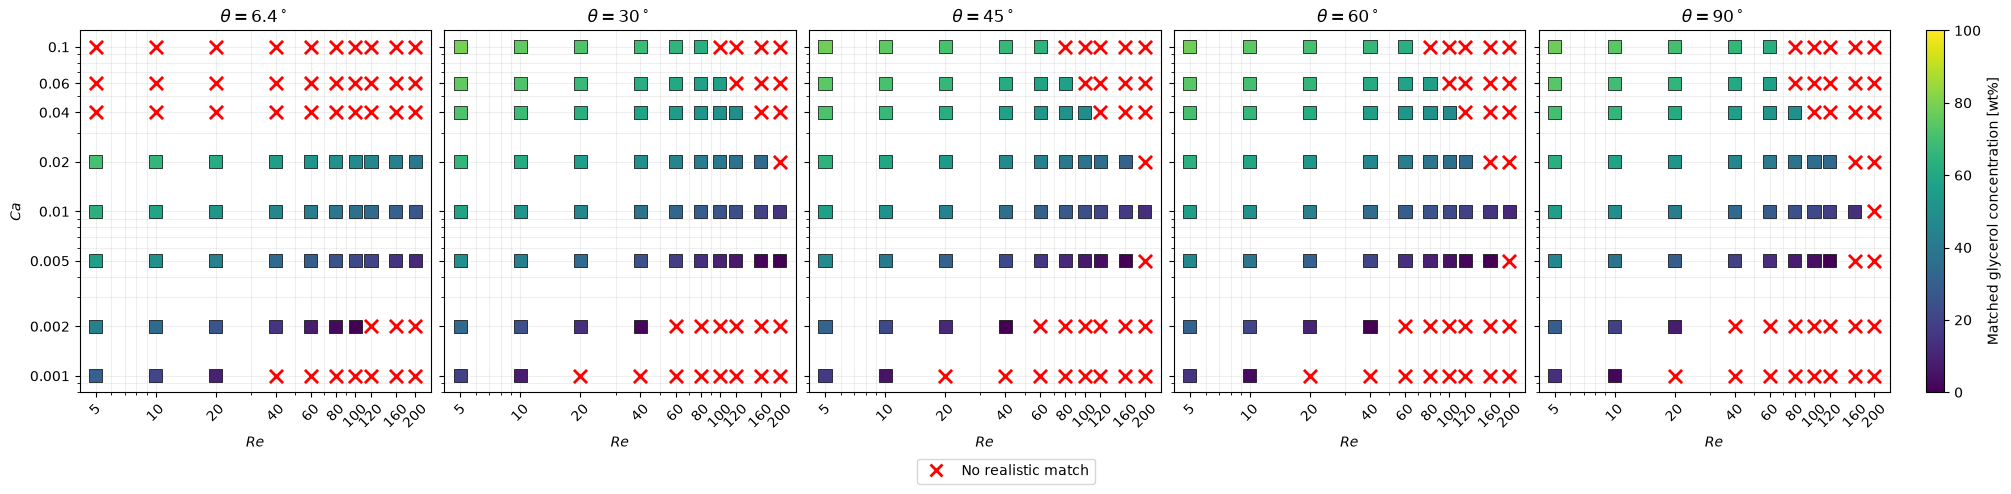

In [14]:
from matplotlib.colors import Normalize
from matplotlib.lines import Line2D

cmap = plt.cm.viridis

concentration_norm = Normalize(
    vmin=0.0,
    vmax=100.0,
)

fig, axes = plt.subplots(
    1,
    len(angles_deg),
    figsize=(20, 4.5),
    sharex=True,
    sharey=True,
    constrained_layout=True,
)

axes = np.atleast_1d(axes)

for ax, angle_deg in zip(axes, angles_deg):

    angle_df = dns_match_df[
        dns_match_df["angle_deg"] == angle_deg
    ]

    realistic_df = angle_df[
        angle_df["realistic"]
    ]

    unrealistic_df = angle_df[
        ~angle_df["realistic"]
    ]

    # Unrealistic DNS points
    # Unrealistic DNS points: red crosses
    ax.scatter(
        unrealistic_df["Re_target"],
        unrealistic_df["Ca_target"],
        color="red",
        marker="x",
        s=90,
        linewidth=2.0,
        zorder=4,
    )

    # Realistic DNS points, colored by glycerol concentration
    ax.scatter(
        realistic_df["Re_target"],
        realistic_df["Ca_target"],
        c=realistic_df["glycerol_wt_percent"],
        cmap=cmap,
        norm=concentration_norm,
        marker="s",
        s=90,
        edgecolor="black",
        linewidth=0.5,
        zorder=3,
    )

    ax.set_xscale("log")
    ax.set_yscale("log")

    ax.set_xticks(dns_Re)
    ax.set_xticklabels(
        [f"{value:g}" for value in dns_Re],
        rotation=45,
    )

    ax.set_yticks(dns_Ca)
    ax.set_yticklabels(
        [f"{value:g}" for value in dns_Ca]
    )

    ax.set_xlabel(r"$Re$")
    ax.set_title(
        rf"$\theta={angle_deg:g}^\circ$"
    )

    ax.grid(
        which="both",
        alpha=0.20,
    )

axes[0].set_ylabel(r"$Ca$")

# Shared concentration colorbar
scalar_mappable = plt.cm.ScalarMappable(
    norm=concentration_norm,
    cmap=cmap,
)

colorbar = fig.colorbar(
    scalar_mappable,
    ax=axes,
    pad=0.02,
)

colorbar.set_label(
    "Matched glycerol concentration [wt%]"
)

# Legend for black points
unrealistic_handle = Line2D(
    [0],
    [0],
    marker="x",
    linestyle="none",
    color="red",
    markeredgewidth=2.0,
    markersize=9,
    label="No realistic match",
)

fig.legend(
    handles=[unrealistic_handle],
    loc="lower center",
    bbox_to_anchor=(0.5, -0.08),
)

plt.show()

In [15]:
# Physical-property ranges for the realistic DNS realizations

realistic_cases = dns_match_df[
    dns_match_df["realistic"]
].copy()

if realistic_cases.empty:

    print("No DNS points satisfy the selected realism criteria.")

else:

    # Recover mixture properties from matched glycerol concentrations
    rho, mu, sigma = glycerol_water_properties(
        realistic_cases["glycerol_wt_percent"].to_numpy()
    )

    realistic_cases["rho_kg_m3"] = rho
    realistic_cases["mu_mPa_s"] = 1e3 * mu
    realistic_cases["sigma_mN_m"] = 1e3 * sigma

    physical_range_summary = pd.DataFrame({
        "Minimum": [
            realistic_cases["glycerol_wt_percent"].min(),
            realistic_cases["h0_mm"].min(),
            realistic_cases["velocity_m_s"].min(),
            realistic_cases["rho_kg_m3"].min(),
            realistic_cases["mu_mPa_s"].min(),
            realistic_cases["sigma_mN_m"].min(),
            realistic_cases["Re_actual"].min(),
            realistic_cases["Ca_actual"].min(),
        ],

        "Maximum": [
            realistic_cases["glycerol_wt_percent"].max(),
            realistic_cases["h0_mm"].max(),
            realistic_cases["velocity_m_s"].max(),
            realistic_cases["rho_kg_m3"].max(),
            realistic_cases["mu_mPa_s"].max(),
            realistic_cases["sigma_mN_m"].max(),
            realistic_cases["Re_actual"].max(),
            realistic_cases["Ca_actual"].max(),
        ],
    },
    index=[
        "Glycerol concentration [wt%]",
        "Film thickness h0 [mm]",
        "Nusselt velocity U_N [m/s]",
        "Density rho [kg/m³]",
        "Dynamic viscosity mu [mPa s]",
        "Surface tension sigma [mN/m]",
        "Actual Reynolds number",
        "Actual Capillary number",
    ])

    display(
        physical_range_summary.style.format({
            "Minimum": "{:.5g}",
            "Maximum": "{:.5g}",
        })
    )

,Minimum,Maximum
Glycerol concentration [wt%],0,79
Film thickness h0 [mm],0.1452,1.8832
Nusselt velocity U_N [m/s],0.027584,0.49887
Density rho [kg/m³],998.2,1214.2
Dynamic viscosity mu [mPa s],1.002,53.819
Surface tension sigma [mN/m],66.004,72.75
Actual Reynolds number,4.9032,201
Actual Capillary number,0.00099184,0.1033


In [16]:
# ---------------------------------------------------------
# Choose the target DNS point
# ---------------------------------------------------------

target_Re = 120.0
target_Ca = 0.01
target_angle_deg = 6.4

# Maximum acceptable relative errors
Re_tolerance = 0.10
Ca_tolerance = 0.10

In [17]:



# ---------------------------------------------------------
# Find the closest realistic physical realization
# ---------------------------------------------------------

candidates = parameter_map[
    (parameter_map["angle_deg"] == target_angle_deg)
    & parameter_map["velocity_realistic"]
].copy()

if candidates.empty:

    print(
        f"No physical cases are available for "
        f"theta = {target_angle_deg:g} degrees."
    )

else:

    # Distance in logarithmic Re-Ca space
    candidates["log_distance"] = np.sqrt(
        np.log10(candidates["Re"] / target_Re)**2
        + np.log10(candidates["Ca"] / target_Ca)**2
    )

    best = candidates.loc[
        candidates["log_distance"].idxmin()
    ].copy()

    Re_error = abs(
        best["Re"] / target_Re - 1.0
    )

    Ca_error = abs(
        best["Ca"] / target_Ca - 1.0
    )

    realistic_match = (
        (Re_error <= Re_tolerance)
        and (Ca_error <= Ca_tolerance)
    )

    if realistic_match:

        match_summary = pd.Series({
            "Target Re": target_Re,
            "Actual Re": best["Re"],
            "Re error [%]": 100.0 * Re_error,

            "Target Ca": target_Ca,
            "Actual Ca": best["Ca"],
            "Ca error [%]": 100.0 * Ca_error,

            "Inclination angle [deg]": target_angle_deg,
            "Glycerol concentration [wt%]":
                best["glycerol_wt_percent"],

            "Film thickness h0 [mm]":
                best["h0_mm"],

            "Nusselt velocity U_N [m/s]":
                best["velocity_m_s"],

            "Density rho [kg/m³]":
                best["rho_kg_m3"],

            "Dynamic viscosity mu [mPa s]":
                1e3 * best["mu_Pa_s"],

            "Surface tension sigma [mN/m]":
                1e3 * best["sigma_N_m"],
        })

        print("A realistic physical match was found.\n")

        display(
            match_summary.to_frame(
                name="Value"
            ).style.format({
                "Value": "{:.6g}"
            })
        )

    else:

        print("No realistic match was found within the selected tolerances.")
        print()
        print("Closest available physical case:")
        print(
            f"  glycerol concentration = "
            f"{best['glycerol_wt_percent']:.2f} wt%"
        )
        print(
            f"  film thickness         = "
            f"{best['h0_mm']:.4f} mm"
        )
        print(
            f"  velocity               = "
            f"{best['velocity_m_s']:.5f} m/s"
        )
        print(
            f"  Re                     = "
            f"{best['Re']:.5g} "
            f"(error = {100 * Re_error:.1f}%)"
        )
        print(
            f"  Ca                     = "
            f"{best['Ca']:.5g} "
            f"(error = {100 * Ca_error:.1f}%)"
        )

A realistic physical match was found.



,Value
Target Re,120
Actual Re,118.427
Re error [%],1.31081
Target Ca,0.01
Actual Ca,0.00992973
Ca error [%],0.702718
Inclination angle [deg],6.4
Glycerol concentration [wt%],34
Film thickness h0 [mm],1.32855
Nusselt velocity U_N [m/s],0.239478


Now I want to create folders and run sims based on these realistic values.

In [18]:
# ---------------------------------------------------------
# Requested DNS parameter space
# ---------------------------------------------------------

selected_angles_deg = np.array(
    [6.4, 45.0, 90.0],
    dtype=float,
)

selected_Re = np.array(
    [10, 20, 40, 80, 120, 200],
    dtype=float,
)

selected_Ca = np.array(
    [
        0.001,
        0.002,
        0.005,
        0.01,
        0.02,
        0.04,
        0.06,
        0.1,
    ],
    dtype=float,
)


# ---------------------------------------------------------
# Physical-realism criteria
# ---------------------------------------------------------

Re_tolerance = 0.10
Ca_tolerance = 0.10

maximum_velocity = 0.50          # m/s
maximum_glycerol_wt = 90.0       # wt%

realistic_case_rows = []


for angle_deg in selected_angles_deg:

    # Physical cases available at this inclination angle
    candidates = parameter_map[
        (parameter_map["angle_deg"] == angle_deg)
        & (
            parameter_map["velocity_m_s"]
            <= maximum_velocity
        )
        & (
            parameter_map["glycerol_wt_percent"]
            <= maximum_glycerol_wt
        )
    ].copy()

    if candidates.empty:
        raise RuntimeError(
            f"No physical candidates are available at "
            f"theta = {angle_deg:g} degrees."
        )

    for Re_target in selected_Re:
        for Ca_target in selected_Ca:

            # Find closest case in logarithmic Re-Ca space
            log_distance = np.sqrt(
                np.log10(
                    candidates["Re"] / Re_target
                )**2
                +
                np.log10(
                    candidates["Ca"] / Ca_target
                )**2
            )

            best = candidates.loc[
                log_distance.idxmin()
            ]

            Re_error = abs(
                best["Re"] / Re_target - 1.0
            )

            Ca_error = abs(
                best["Ca"] / Ca_target - 1.0
            )

            realistic = (
                (Re_error <= Re_tolerance)
                and
                (Ca_error <= Ca_tolerance)
            )

            realistic_case_rows.append({
                "Re_target": Re_target,
                "Ca_target": Ca_target,
                "angle_deg": angle_deg,
                "realistic": realistic,

                "Re_actual": best["Re"],
                "Ca_actual": best["Ca"],

                "Re_error_percent":
                    100.0 * Re_error,

                "Ca_error_percent":
                    100.0 * Ca_error,

                "glycerol_wt_percent":
                    best["glycerol_wt_percent"],

                "h0_mm":
                    best["h0_mm"],

                "velocity_m_s":
                    best["velocity_m_s"],

                "rho_kg_m3":
                    best["rho_kg_m3"],

                "mu_Pa_s":
                    best["mu_Pa_s"],

                "sigma_N_m":
                    best["sigma_N_m"],
            })


selected_case_df = pd.DataFrame(
    realistic_case_rows
)

realistic_case_df = (
    selected_case_df[
        selected_case_df["realistic"]
    ]
    .copy()
    .reset_index(drop=True)
)

unrealistic_case_df = (
    selected_case_df[
        ~selected_case_df["realistic"]
    ]
    .copy()
    .reset_index(drop=True)
)


print(
    f"Total requested cases: "
    f"{len(selected_case_df)}"
)

print(
    f"Realistic cases: "
    f"{len(realistic_case_df)}"
)

print(
    f"Unrealistic cases: "
    f"{len(unrealistic_case_df)}"
)


display(
    realistic_case_df[
        [
            "Re_target",
            "Ca_target",
            "angle_deg",
            "glycerol_wt_percent",
            "h0_mm",
            "velocity_m_s",
            "rho_kg_m3",
            "mu_Pa_s",
            "Re_actual",
            "Ca_actual",
            "Re_error_percent",
            "Ca_error_percent",
        ]
    ]
)

Total requested cases: 144
Realistic cases: 83
Unrealistic cases: 61


,Re_target,Ca_target,angle_deg,glycerol_wt_percent,h0_mm,velocity_m_s,rho_kg_m3,mu_Pa_s,Re_actual,Ca_actual,Re_error_percent,Ca_error_percent
0,10.0,0.001,6.4,21.0,0.433963,0.039648,1050.069255688259,0.001818,9.937616,0.001012,0.623840,1.203637
1,10.0,0.002,6.4,34.5,0.593339,0.046901,1084.5605471737638,0.002967,10.170730,0.001984,1.707295,0.795099
2,10.0,0.005,6.4,50.0,0.914963,0.057403,1128.7,0.006000,9.880234,0.005006,1.197663,0.121895
3,10.0,0.010,6.4,59.0,1.281458,0.068321,1155.6308974702245,0.010124,9.993243,0.010173,0.067572,1.732495
4,10.0,0.020,6.4,66.0,1.752083,0.080288,1176.2229574231765,0.016393,10.093643,0.019555,0.936431,2.226057
...,...,...,...,...,...,...,...,...,...,...,...,...
78,80.0,0.020,90.0,38.0,0.622591,0.405833,1094.0549345054944,0.003417,80.899215,0.019848,1.124019,0.757668
79,80.0,0.040,90.0,49.5,0.871974,0.479518,1127.2244796118343,0.005845,80.641371,0.040709,0.801713,1.772911
80,120.0,0.005,90.0,0.0,0.333044,0.361328,998.2,0.001002,119.881856,0.004977,0.098453,0.467175
81,120.0,0.010,90.0,18.5,0.455358,0.421658,1043.9198781376517,0.001679,119.404139,0.009912,0.496551,0.879519


In [19]:
display(
    unrealistic_case_df[
        [
            "Re_target",
            "Ca_target",
            "angle_deg",
            "Re_actual",
            "Ca_actual",
            "Re_error_percent",
            "Ca_error_percent",
        ]
    ]
)

,Re_target,Ca_target,angle_deg,Re_actual,Ca_actual,Re_error_percent,Ca_error_percent
0,10.0,0.04,6.4,9.543600,0.025787,4.563995,35.533360
1,10.0,0.06,6.4,9.543600,0.025787,4.563995,57.022240
2,10.0,0.10,6.4,9.543600,0.025787,4.563995,74.213344
3,20.0,0.04,6.4,19.888391,0.025277,0.558046,36.806395
4,20.0,0.06,6.4,19.888391,0.025277,0.558046,57.870930
...,...,...,...,...,...,...,...
56,200.0,0.01,90.0,170.825190,0.009199,14.587405,8.005311
57,200.0,0.02,90.0,130.022332,0.017039,34.988834,14.803865
58,200.0,0.04,90.0,97.471445,0.032078,51.264278,19.806022
59,200.0,0.06,90.0,80.467987,0.048652,59.766007,18.913053


In [20]:
from pathlib import Path
import shutil
import re

# ---------------------------------------------------------
# Source and destination
# ---------------------------------------------------------

simulation_root = Path(
    "/blue/bala1s/krishnap.kalivel/TLFHydrodynamics/thinfilm-closure-ml/datasets/BasC/param_space"
)

files_to_copy = [
    simulation_root / "filmflow",
    simulation_root / "filmflow_restart",
    simulation_root / "run.sh",
]

In [21]:


# ---------------------------------------------------------
# Validate source files before creating anything
# ---------------------------------------------------------

missing_files = [
    file for file in files_to_copy
    if not file.is_file()
]

if missing_files:
    missing_text = "\n".join(
        str(file) for file in missing_files
    )

    raise FileNotFoundError(
        "The following source files were not found:\n"
        + missing_text
    )


# ---------------------------------------------------------
# Folder-name formatting
# ---------------------------------------------------------

def format_Re_for_folder(Re):
    """
    Examples:
        10  -> 010
        80  -> 080
        120 -> 120
        200 -> 200
    """
    return f"{int(round(Re)):03d}"


def format_Ca_for_folder(Ca):
    """
    Examples:
        0.001 -> 0_001
        0.005 -> 0_005
        0.010 -> 0_010
        0.100 -> 0_100
    """
    return f"{Ca:.3f}".replace(".", "_")


def format_angle_for_folder(angle_deg):
    """
    Examples:
        6.4 -> 6_4
        45  -> 45
        90  -> 90
    """
    if float(angle_deg).is_integer():
        return str(int(angle_deg))

    return (
        f"{angle_deg:g}"
        .replace(".", "_")
    )


def make_case_directory_name(
    Re,
    Ca,
    angle_deg,
):
    return (
        f"Re{format_Re_for_folder(Re)}"
        f"_Ca{format_Ca_for_folder(Ca)}"
        f"_theta{format_angle_for_folder(angle_deg)}"
    )


In [22]:
import re
import shutil
import pandas as pd


# ---------------------------------------------------------
# Validate template files before creating directories
# ---------------------------------------------------------

source_filmflow = simulation_root / "filmflow"
source_filmflow_restart = simulation_root / "filmflow_restart"
source_run_file = simulation_root / "run.sh"
source_makefile = simulation_root / "Makefile"

required_source_files = [
    source_filmflow,
    source_filmflow_restart,
    source_run_file,
]

missing_source_files = [
    path for path in required_source_files
    if not path.is_file()
]

if missing_source_files:
    raise FileNotFoundError(
        "Missing source files:\n"
        + "\n".join(
            str(path)
            for path in missing_source_files
        )
    )


# Read the run script only once
run_template = source_run_file.read_text(
    encoding="utf-8"
)


# ---------------------------------------------------------
# Create realistic simulation cases
# ---------------------------------------------------------

created_case_rows = []
skipped_case_rows = []

for _, case in realistic_case_df.iterrows():

    Re_target = float(case["Re_target"])
    Ca_target = float(case["Ca_target"])
    angle_deg = float(case["angle_deg"])

    directory_name = make_case_directory_name(
        Re=Re_target,
        Ca=Ca_target,
        angle_deg=angle_deg,
    )

    case_directory = (
        simulation_root / directory_name
    )


    # -----------------------------------------------------
    # Skip existing directories completely
    # -----------------------------------------------------

    if case_directory.exists():

        print(
            f"Skipping existing directory: "
            f"{directory_name}"
        )

        skipped_case_rows.append({
            "directory": directory_name,
            "path": str(case_directory),
            "reason": "Directory already exists",
        })

        continue


    # -----------------------------------------------------
    # Prepare the modified run.sh contents
    # -----------------------------------------------------

    job_name = (
        f"R{format_Re_for_folder(Re_target)}"
        f"_C{format_Ca_for_folder(Ca_target)}"
        f"_T{format_angle_for_folder(angle_deg)}"
    )

    modified_run_text, replacements = re.subn(
        pattern=(
            r"^#SBATCH[ \t]+"
            r"--job-name(?:=|[ \t]+)\S+"
        ),
        repl=f"#SBATCH --job-name={job_name}",
        string=run_template,
        count=1,
        flags=re.MULTILINE,
    )

    if replacements != 1:
        raise RuntimeError(
            "Could not find exactly one "
            "'#SBATCH --job-name' directive in "
            f"{source_run_file}"
        )


    # -----------------------------------------------------
    # Matched physical properties
    # -----------------------------------------------------

    rho_l = float(case["rho_kg_m3"])
    mu_l = float(case["mu_Pa_s"])

    glycerol_wt = float(
        case["glycerol_wt_percent"]
    )

    h0_mm = float(case["h0_mm"])
    velocity = float(case["velocity_m_s"])


    # -----------------------------------------------------
    # Prepare params.in contents
    # -----------------------------------------------------

    params_text = f"""LX = 800
MAXLEVEL = 14
AR = 128
Zoom = 128
CFL = 0.1
CA = {Ca_target:.6g}
RE = {Re_target:.1f}
ANGLE_DEG = {angle_deg:.6g}
RHO_L = {rho_l:.8g}
MU_L = {mu_l:.8g}
T_OUT = 10
T_DUMP = 50
T_END = 2000
F0_NOISE = 0.025
FCUT_DIM = 28.0
NOISE_SEED = 12345
MNOISE = 1000
"""


    # -----------------------------------------------------
    # Create the directory
    # -----------------------------------------------------

    case_directory.mkdir(
        parents=False,
        exist_ok=False,
    )


    # -----------------------------------------------------
    # Copy the executables
    # -----------------------------------------------------

    shutil.copy2(
        source_filmflow,
        case_directory / "filmflow",
    )

    shutil.copy2(
        source_filmflow_restart,
        case_directory / "filmflow_restart",
    )
    
    shutil.copy2(
        source_makefile,
        case_directory / "Makefile",
    )


    # -----------------------------------------------------
    # Write the customized run.sh
    # -----------------------------------------------------

    destination_run_file = (
        case_directory / "run.sh"
    )

    destination_run_file.write_text(
        modified_run_text,
        encoding="utf-8",
    )

    # Give the new run.sh the permissions of the template
    shutil.copymode(
        source_run_file,
        destination_run_file,
    )


    # -----------------------------------------------------
    # Write params.in
    # -----------------------------------------------------

    params_file = (
        case_directory / "params.in"
    )

    params_file.write_text(
        params_text,
        encoding="utf-8",
    )


    # -----------------------------------------------------
    # Ensure scripts and executables are executable
    # -----------------------------------------------------

    for executable_name in [
        "filmflow",
        "filmflow_restart",
    ]:

        executable_path = (
            case_directory / executable_name
        )

        executable_path.chmod(
            executable_path.stat().st_mode
            | 0o111
        )


    # -----------------------------------------------------
    # Record the newly created case
    # -----------------------------------------------------

    created_case_rows.append({
        "directory": directory_name,
        "job_name": job_name,
        "path": str(case_directory),
        "Re": Re_target,
        "Ca": Ca_target,
        "angle_deg": angle_deg,
        "glycerol_wt_percent": glycerol_wt,
        "h0_mm": h0_mm,
        "velocity_m_s": velocity,
        "rho_kg_m3": rho_l,
        "mu_Pa_s": mu_l,
    })

    print(
        f"Created: {directory_name} "
        f"[job name: {job_name}]"
    )


# ---------------------------------------------------------
# Summarize the result
# ---------------------------------------------------------

created_case_df = pd.DataFrame(
    created_case_rows
)

skipped_case_df = pd.DataFrame(
    skipped_case_rows
)

print()

print(
    f"New directories created: "
    f"{len(created_case_df)}"
)

print(
    f"Existing directories skipped: "
    f"{len(skipped_case_df)}"
)

if not created_case_df.empty:
    print("\nCreated cases:")
    display(created_case_df)

if not skipped_case_df.empty:
    print("\nSkipped cases:")
    display(skipped_case_df)

Skipping existing directory: Re010_Ca0_001_theta6_4
Skipping existing directory: Re010_Ca0_002_theta6_4
Skipping existing directory: Re010_Ca0_005_theta6_4
Skipping existing directory: Re010_Ca0_010_theta6_4
Skipping existing directory: Re010_Ca0_020_theta6_4
Skipping existing directory: Re020_Ca0_001_theta6_4
Skipping existing directory: Re020_Ca0_002_theta6_4
Skipping existing directory: Re020_Ca0_005_theta6_4
Skipping existing directory: Re020_Ca0_010_theta6_4
Skipping existing directory: Re020_Ca0_020_theta6_4
Skipping existing directory: Re040_Ca0_002_theta6_4
Skipping existing directory: Re040_Ca0_005_theta6_4
Skipping existing directory: Re040_Ca0_010_theta6_4
Skipping existing directory: Re040_Ca0_020_theta6_4
Skipping existing directory: Re080_Ca0_002_theta6_4
Skipping existing directory: Re080_Ca0_005_theta6_4
Skipping existing directory: Re080_Ca0_010_theta6_4
Skipping existing directory: Re080_Ca0_020_theta6_4
Skipping existing directory: Re120_Ca0_005_theta6_4
Skipping exi

,directory,job_name,path,Re,Ca,angle_deg,glycerol_wt_percent,h0_mm,velocity_m_s,rho_kg_m3,mu_Pa_s
0,Re010_Ca0_005_theta45,R010_C0_005_T45,/blue/bala1s/krishnap.kalivel/TLFHydrodynamics...,10.0,0.005,45.0,40.5,0.371131,0.092229,1101.002475,0.003802
1,Re040_Ca0_002_theta45,R040_C0_002_T45,/blue/bala1s/krishnap.kalivel/TLFHydrodynamics...,40.0,0.002,45.0,0.0,0.255595,0.150482,998.200000,0.001002
2,Re040_Ca0_005_theta45,R040_C0_005_T45,/blue/bala1s/krishnap.kalivel/TLFHydrodynamics...,40.0,0.005,45.0,22.0,0.380169,0.187159,1052.540168,0.001879
3,Re080_Ca0_005_theta45,R080_C0_005_T45,/blue/bala1s/krishnap.kalivel/TLFHydrodynamics...,80.0,0.005,45.0,11.0,0.389428,0.266956,1025.758334,0.001347
4,Re120_Ca0_005_theta45,R120_C0_005_T45,/blue/bala1s/krishnap.kalivel/TLFHydrodynamics...,120.0,0.005,45.0,3.5,0.394142,0.329697,1007.076516,0.001097
5,Re040_Ca0_100_theta90,R040_C0_100_T90,/blue/bala1s/krishnap.kalivel/TLFHydrodynamics...,40.0,0.100,90.0,66.0,1.328554,0.414140,1176.222957,0.016393



Skipped cases:


,directory,path,reason
0,Re010_Ca0_001_theta6_4,/blue/bala1s/krishnap.kalivel/TLFHydrodynamics...,Directory already exists
1,Re010_Ca0_002_theta6_4,/blue/bala1s/krishnap.kalivel/TLFHydrodynamics...,Directory already exists
2,Re010_Ca0_005_theta6_4,/blue/bala1s/krishnap.kalivel/TLFHydrodynamics...,Directory already exists
3,Re010_Ca0_010_theta6_4,/blue/bala1s/krishnap.kalivel/TLFHydrodynamics...,Directory already exists
4,Re010_Ca0_020_theta6_4,/blue/bala1s/krishnap.kalivel/TLFHydrodynamics...,Directory already exists
...,...,...,...
72,Re080_Ca0_020_theta90,/blue/bala1s/krishnap.kalivel/TLFHydrodynamics...,Directory already exists
73,Re080_Ca0_040_theta90,/blue/bala1s/krishnap.kalivel/TLFHydrodynamics...,Directory already exists
74,Re120_Ca0_005_theta90,/blue/bala1s/krishnap.kalivel/TLFHydrodynamics...,Directory already exists
75,Re120_Ca0_010_theta90,/blue/bala1s/krishnap.kalivel/TLFHydrodynamics...,Directory already exists


In [23]:
from pathlib import Path
import shutil
import pandas as pd


simulation_root = Path(
    "/blue/bala1s/krishnap.kalivel/"
    "TLFHydrodynamics/thinfilm-closure-ml/"
    "datasets/BasC/param_space"
).resolve()

# Safety switch: keep False for the first run
DELETE_CONFIRMED = False


# ---------------------------------------------------------
# Identify simulation directories with no HDF5 data
# ---------------------------------------------------------

empty_case_rows = []

for case_directory in sorted(
    simulation_root.glob("Re*_Ca*_theta*")
):
    if not case_directory.is_dir():
        continue

    # Do not follow or delete symbolic links
    if case_directory.is_symlink():
        continue

    case_directory = case_directory.resolve()

    # Verify that the candidate is directly inside simulation_root
    if case_directory.parent != simulation_root:
        raise RuntimeError(
            f"Unsafe deletion candidate detected: "
            f"{case_directory}"
        )

    output_directory = (
        case_directory / "output"
    )

    if output_directory.is_dir():
        h5_files = list(
            output_directory.glob("*.h5")
        )
        output_exists = True
    else:
        h5_files = []
        output_exists = False

    if len(h5_files) == 0:
        empty_case_rows.append({
            "directory":
                case_directory.name,

            "path":
                str(case_directory),

            "output_directory_exists":
                output_exists,

            "num_h5_files":
                0,
        })


empty_case_df = pd.DataFrame(
    empty_case_rows
)

print(
    f"Found {len(empty_case_df)} simulation "
    f"directories with no HDF5 data."
)

display(empty_case_df)




Found 62 simulation directories with no HDF5 data.


,directory,path,output_directory_exists,num_h5_files
0,Re010_Ca0_001_theta45,/blue/bala1s/krishnap.kalivel/TLFHydrodynamics...,False,0
1,Re010_Ca0_001_theta6_4,/blue/bala1s/krishnap.kalivel/TLFHydrodynamics...,False,0
2,Re010_Ca0_001_theta90,/blue/bala1s/krishnap.kalivel/TLFHydrodynamics...,False,0
3,Re010_Ca0_002_theta45,/blue/bala1s/krishnap.kalivel/TLFHydrodynamics...,False,0
4,Re010_Ca0_002_theta6_4,/blue/bala1s/krishnap.kalivel/TLFHydrodynamics...,False,0
...,...,...,...,...
57,Re080_Ca0_060_theta45,/blue/bala1s/krishnap.kalivel/TLFHydrodynamics...,False,0
58,Re120_Ca0_005_theta45,/blue/bala1s/krishnap.kalivel/TLFHydrodynamics...,False,0
59,Re120_Ca0_005_theta6_4,/blue/bala1s/krishnap.kalivel/TLFHydrodynamics...,False,0
60,Re120_Ca0_020_theta45,/blue/bala1s/krishnap.kalivel/TLFHydrodynamics...,False,0


In [24]:
DELETE_CONFIRMED = True

In [25]:
DELETE_CONFIRMED = False

In [26]:
# ---------------------------------------------------------
# Delete only after explicit confirmation
# ---------------------------------------------------------

if not DELETE_CONFIRMED:

    print()
    print("PREVIEW ONLY: no directories were deleted.")
    print(
        "Inspect empty_case_df, then set "
        "DELETE_CONFIRMED = True and rerun this cell."
    )

else:

    deleted_directories = []

    for directory_text in empty_case_df["path"]:

        case_directory = Path(
            directory_text
        ).resolve()

        # Repeat safety checks immediately before deletion
        if (
            case_directory.parent
            != simulation_root
        ):
            raise RuntimeError(
                f"Refusing to delete unsafe path: "
                f"{case_directory}"
            )

        if not case_directory.name.startswith("Re"):
            raise RuntimeError(
                f"Unexpected directory name: "
                f"{case_directory.name}"
            )

        if (
            case_directory.exists()
            and not case_directory.is_symlink()
        ):
            shutil.rmtree(case_directory)

            deleted_directories.append(
                case_directory.name
            )

            print(
                f"Deleted: "
                f"{case_directory.name}"
            )

    print()
    print(
        f"Deleted {len(deleted_directories)} "
        f"simulation directories."
    )


PREVIEW ONLY: no directories were deleted.
Inspect empty_case_df, then set DELETE_CONFIRMED = True and rerun this cell.
